In [1]:
import matplotlib.pyplot as plt
import numpy as np
import os
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping
from tensorflow.keras import regularizers

# ===== 환경 설정 =====
# 데이터가 저장된 폴더 (전처리 완료된 npz 파일 경로)
DATA_DIR = "data/processed"

# 클래스 이름 (폴더 순서대로 0,1,2,3 매핑)
CLASSES = ["Chatting", "Game", "web_surfing", "Writing"]

# 학습 파라미터
BATCH_SIZE = 32
EPOCHS = 20
IMG_HEIGHT = 64  # 멜 스펙트로그램의 높이 (n_mels)

print(f"TensorFlow Version: {tf.__version__}")
print(f"사용 장치: {tf.config.list_physical_devices('GPU')}")

TensorFlow Version: 2.11.0
사용 장치: []


In [2]:
def load_dataset_from_npz(split, batch_size):
    path = os.path.join(DATA_DIR, f"{split}.npz")
    if not os.path.exists(path):
        raise FileNotFoundError(f"파일을 찾을 수 없습니다: {path}")
    
    # 1. npz 파일 로드
    data = np.load(path)
    X = data['X'] # Shape: (N, 64, Time)
    y = data['y'] # Shape: (N,)
    
    # 2. 채널 차원 추가
    # CNN은 (Height, Width, Channel) 형태를 원하므로 (N, 64, Time, 1)로 변환
    X = np.expand_dims(X, axis=-1)
    
    # 3. tf.data.Dataset 생성
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    
    # 4. 배치 적용 (drop_remainder=False로 설정해 남은 데이터도 버리지 않음)
    ds = ds.batch(batch_size, drop_remainder=False)
    return ds

print("--- 데이터셋 로딩 중 ---")
train_ds = load_dataset_from_npz("train", BATCH_SIZE)
val_ds = load_dataset_from_npz("val", BATCH_SIZE)
test_ds = load_dataset_from_npz("test", BATCH_SIZE)

# 데이터 형태 확인
for images, labels in train_ds.take(1):
    print(f"Input Shape: {images.shape}")  # 예: (32, 64, Time, 1)
    print(f"Label Shape: {labels.shape}")  # 예: (32,)

--- 데이터셋 로딩 중 ---
Input Shape: (32, 64, 1001, 1)
Label Shape: (32,)


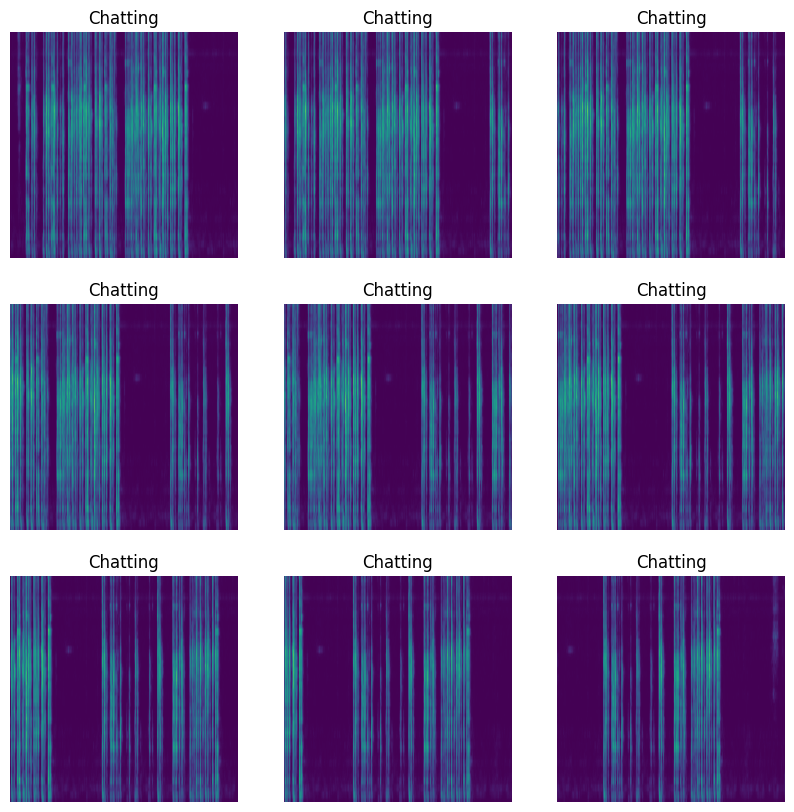

In [3]:
plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
    # 최대 9개까지만 출력
    for i in range(min(9, images.shape[0])):
        ax = plt.subplot(3, 3, i + 1)
        
        # (64, Time, 1) -> (64, Time)으로 차원 축소 후 시각화
        img_array = images[i].numpy().squeeze()
        
        plt.imshow(img_array, aspect='auto', origin='lower', cmap='viridis')
        plt.title(CLASSES[labels[i]])
        plt.axis("off")
plt.show()

In [4]:
AUTOTUNE = tf.data.AUTOTUNE

# 학습 데이터: 셔플(Shuffle) 추가
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)

# 검증/테스트 데이터: 셔플 불필요
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.cache().prefetch(buffer_size=AUTOTUNE)

In [5]:
num_classes = len(CLASSES)
num_classes = len(CLASSES)

model = Sequential([
    # Input
    layers.Input(shape=(IMG_HEIGHT, None, 1)),
    
    # [Block 1]
    layers.Conv2D(16, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.BatchNormalization(),
    
    # [Block 2]
    layers.Conv2D(32, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.BatchNormalization(),
    
    # [Block 3]
    layers.Conv2D(64, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.BatchNormalization(),
    
    # [Global Pooling]
    layers.GlobalAveragePooling2D(),
    
    # [Classifier 수정된 부분 ★]
    # 1. 뉴런 수 조금 줄임 (128 -> 64) : 모델 경량화
    # 2. L2 규제 추가 : 가중치가 너무 커지는 것 방지
    layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    
    # 3. Dropout 강화 (0.4 -> 0.5) : 더 강하게 끄기
    layers.Dropout(0.5),
    
    layers.Dense(num_classes)
])

# [Optimizer 수정된 부분 ★]
# 학습률(Learning Rate)을 0.001 -> 0.0001로 낮춤 (더 천천히 꼼꼼하게 학습)
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 64, None, 16)      160       
                                                                 
 max_pooling2d (MaxPooling2D  (None, 32, None, 16)     0         
 )                                                               
                                                                 
 batch_normalization (BatchN  (None, 32, None, 16)     64        
 ormalization)                                                   
                                                                 
 conv2d_1 (Conv2D)           (None, 32, None, 32)      4640      
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 16, None, 32)     0         
 2D)                                                             
                                                        

In [6]:
# 1. 모델 저장 (그대로 유지)
checkpoint_cb = ModelCheckpoint(
    "best_model.keras", 
    save_best_only=True, 
    monitor="val_accuracy",
    mode="max",
    verbose=1
)

# 2. 조기 종료 (그대로 유지)
early_stopping_cb = EarlyStopping(
    monitor="val_loss",
    patience=7,               # 참을성 조금 늘림 (5 -> 7)
    restore_best_weights=True
)

# 3. [추가된 부분 ★] 학습률 자동 감소
# 검증 손실(val_loss)이 3번(patience) 동안 안 줄어들면 학습률을 반(factor=0.5)으로 줄임
reduce_lr_cb = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

print("\n--- 학습 시작 (튜닝 버전) ---")
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,  # 학습률을 낮췄으니 에포크를 조금 늘림 (20 -> 30)
    callbacks=[checkpoint_cb, early_stopping_cb, reduce_lr_cb]
)


--- 학습 시작 (튜닝 버전) ---
Epoch 1/30
327/327 [==============================] - ETA: 0s - loss: 1.3137 - accuracy: 0.4549
Epoch 1: val_accuracy improved from -inf to 0.96226, saving model to best_model.keras
327/327 [==============================] - 92s 277ms/step - loss: 1.3137 - accuracy: 0.4549 - val_loss: 0.5598 - val_accuracy: 0.9623 - lr: 1.0000e-04
Epoch 2/30
327/327 [==============================] - ETA: 0s - loss: 1.1492 - accuracy: 0.5923
Epoch 2: val_accuracy did not improve from 0.96226
327/327 [==============================] - 91s 279ms/step - loss: 1.1492 - accuracy: 0.5923 - val_loss: 2.1752 - val_accuracy: 0.0660 - lr: 1.0000e-04
Epoch 3/30
327/327 [==============================] - ETA: 0s - loss: 1.0667 - accuracy: 0.6241
Epoch 3: val_accuracy did not improve from 0.96226
327/327 [==============================] - 92s 282ms/step - loss: 1.0667 - accuracy: 0.6241 - val_loss: 1.9501 - val_accuracy: 0.2120 - lr: 1.0000e-04
Epoch 4/30
327/327 [============================

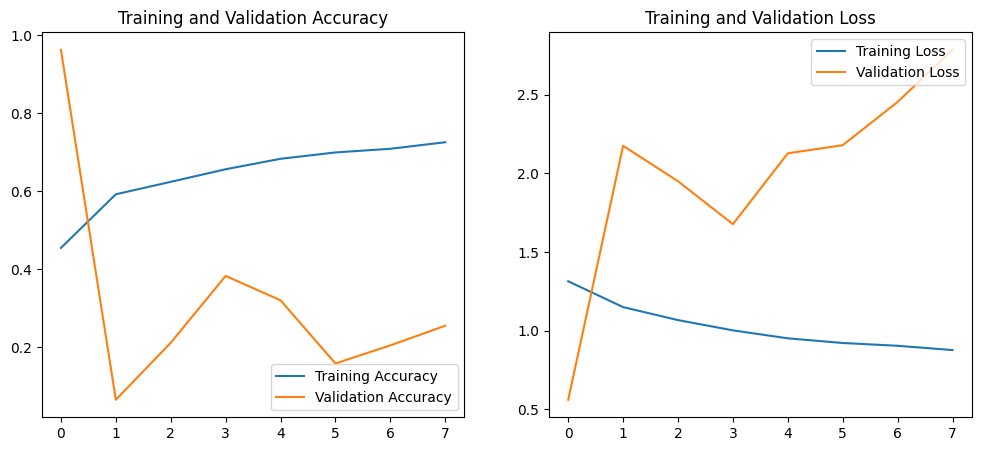

In [7]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

real_epochs = range(len(acc)) # 조기 종료 되었을 수 있으므로 실제 길이 사용

plt.figure(figsize=(12, 5))

# 정확도 그래프
plt.subplot(1, 2, 1)
plt.plot(real_epochs, acc, label='Training Accuracy')
plt.plot(real_epochs, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

# 손실 그래프
plt.subplot(1, 2, 2)
plt.plot(real_epochs, loss, label='Training Loss')
plt.plot(real_epochs, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

In [8]:
# 저장된 최고의 모델 불러오기
saved_model = tf.keras.models.load_model("best_model.keras")
print("★ 최고 성능 모델(best_model.keras) 로드 완료")

# 테스트 데이터 하나 꺼내서 예측해보기
print("\n[샘플 예측 테스트]")
for images, labels in test_ds.take(1):
    sample_img = images[0]
    true_label = labels[0]
    
    # 배치 차원 추가 (64, T, 1) -> (1, 64, T, 1)
    img_input = tf.expand_dims(sample_img, 0)
    
    # 예측
    predictions = saved_model.predict(img_input)
    score = tf.nn.softmax(predictions[0])
    
    predicted_label = np.argmax(score)
    confidence = 100 * np.max(score)
    
    print(f"정답 클래스: {CLASSES[true_label]}")
    print(f"예측 클래스: {CLASSES[predicted_label]} ({confidence:.2f}% 확신)")
    break

# 전체 테스트셋 정확도 평가
loss, acc = saved_model.evaluate(test_ds)
print(f"\n최종 테스트 정확도: {acc*100:.2f}%")

★ 최고 성능 모델(best_model.keras) 로드 완료

[샘플 예측 테스트]
1/1 [==============================] - 0s 86ms/step
정답 클래스: Chatting
예측 클래스: Writing (46.81% 확신)
35/35 [==============================] - 2s 65ms/step - loss: 1.3461 - accuracy: 0.5918

최종 테스트 정확도: 59.18%
